# Explainable Credit Approval Modelling with a Calibrated Hybrid Ensemble
**A Performance, Attribution and Sensitive-Feature Audit of Linear, Tree-Based and Gated Deep Learning Models on the Australian Credit Dataset**

Companion notebook to the research paper. Dataset: Statlog Australian Credit Approval (`australian.dat`, 690 applications, 14 attributes).

**Models benchmarked (5):** Logistic Regression · Random Forest · XGBoost · Deep Gated Tabular Network (DGTN) · **Proposed Hybrid-TabNet-Ensemble**

> The hybrid, as described in the paper (Section III-E), also uses **Extra Trees** and **CatBoost** as *silent members*. They are trained inside the ensemble but are not reported as separate benchmarks. Everything else (Decision Tree, plain MLP, Soft-Voting ensemble) has been removed.

| Section | Content | Paper reference |
|---|---|---|
| 1 | Setup & configuration | – |
| 2 | Data loading & domain feature engineering | Sec. III-A, III-B, Table I |
| 3 | Exploratory data analysis | Figs. 1–4, Table III |
| 4 | Leakage-free preprocessing & 5-fold CV cache | Sec. III-C |
| 5 | Models: benchmarks, DGTN, hybrid ensemble | Sec. III-D, III-E, Table II |
| 6 | Evaluation: metrics, confusion matrices, CV AUC | Tables IV–VI |
| 7 | SHAP global explanations | Figs. 5, 6, 9–11, Table VII |
| 8 | SHAP local explanations (waterfalls) | Figs. 7, 8 |
| 9 | LIME vs SHAP cross-validation | Fig. 12, Table VIII |
| 10 | Sensitive-attribute fairness audit | Figs. 13, 14, Table IX |

Figure numbers and file names follow the **paper's** numbering. All figures are saved to `paper_figures/`.

## 1. Setup & Configuration

In [ ]:
# Uncomment and run once if any package is missing
# !pip install numpy pandas matplotlib seaborn scikit-learn xgboost catboost shap lime

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import RobustScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, matthews_corrcoef
)
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

warnings.filterwarnings("ignore")

In [2]:
# ---- Global configuration ----
DATA_PATH    = "australian.dat"   # place the file next to this notebook
FIG_DIR      = "paper_figures"
RANDOM_STATE = 42                 # model / CV seed
SPLIT_SEED   = 7                  # train-test split seed
TEST_SIZE    = 0.20
WOE_SMOOTH   = 1.5                # Bayesian smoothing for weight-of-evidence

np.random.seed(RANDOM_STATE)
os.makedirs(FIG_DIR, exist_ok=True)

plt.rcParams["figure.dpi"]       = 120
plt.rcParams["savefig.dpi"]      = 300
plt.rcParams["font.sans-serif"]  = "DejaVu Sans"

# Class colours used across all figures
CLASS_PALETTE = {"Approved (1)": "#2ecc71", "Rejected (0)": "#ef5350"}

def save_fig(name):
    # Save the current figure into FIG_DIR.
    plt.savefig(f"{FIG_DIR}/{name}", bbox_inches="tight")

print("Setup complete.")

Setup complete.


## 2. Data Loading & Domain Feature Engineering


In [3]:
col_names = [
    "gender",                  # A1 : binary demographic indicator (0/1)
    "age",                     # A2 : applicant age (continuous)
    "debt_ratio",              # A3 : debt obligation ratio (continuous)
    "marital_status",          # A4 : marital / civil status (categorical)
    "bank_customer_type",      # A5 : bank account / customer tier (categorical)
    "education_level",         # A6 : education / qualification level (categorical)
    "years_employed",          # A7 : employment tenure in years (continuous)
    "no_prior_default",        # A8 : 1 = clean history, 0 = prior default
    "is_employed",             # A9 : 1 = employed, 0 = unemployed
    "existing_credits_count",  # A10: number of existing credit accounts
    "drivers_license",         # A11: ID verification indicator (0/1)
    "citizenship_status",      # A12: citizenship / residency status (categorical)
    "loan_balance",            # A13: loan / obligation balance (continuous)
    "savings_income",          # A14: liquid savings / income amount (continuous)
    "target",                  # 0 = Rejected (high risk), 1 = Approved (creditworthy)
]

if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(f"'{DATA_PATH}' not found. Put it in the same folder as this notebook.")

raw_df = pd.read_csv(DATA_PATH, sep=r"\s+", header=None, names=col_names, na_values=["?"])
print(f"Loaded {DATA_PATH}: {raw_df.shape[0]} rows x {raw_df.shape[1]} columns")
raw_df.head()

Loaded australian.dat: 690 rows x 15 columns


,gender,age,debt_ratio,marital_status,bank_customer_type,education_level,years_employed,no_prior_default,is_employed,existing_credits_count,drivers_license,citizenship_status,loan_balance,savings_income,target
0,1,22.08,11.46,2,4,4,1.585,0,0,0,1,2,100,1213,0
1,0,22.67,7.00,2,8,4,0.165,0,0,0,0,2,160,1,0
2,0,29.58,1.75,1,4,4,1.250,0,0,0,1,2,280,1,0
3,0,21.67,11.50,1,5,3,0.000,1,1,11,1,2,0,1,1
4,1,20.17,8.17,2,6,4,1.960,1,1,14,0,2,60,159,1


###  Feature groups and type handling

In [4]:
X = raw_df.drop(columns=["target"]).copy()
y = raw_df["target"].astype(int).values

num_cols       = ["age", "debt_ratio", "years_employed", "existing_credits_count", "loan_balance", "savings_income"]
bin_cols       = ["gender", "no_prior_default", "is_employed", "drivers_license"]
multi_cat_cols = ["marital_status", "bank_customer_type", "education_level", "citizenship_status"]

for c in num_cols:                       # continuous -> numeric, median-impute
    X[c] = pd.to_numeric(X[c], errors="coerce")
    X[c] = X[c].fillna(X[c].median())

for c in bin_cols:                       # binary -> float
    X[c] = pd.to_numeric(X[c], errors="coerce").fillna(0).astype(float)

for c in multi_cat_cols:                 # multi-category -> string
    X[c] = X[c].astype(str)

print("Numeric :", num_cols)
print("Binary  :", bin_cols)
print("Category:", multi_cat_cols)

Numeric : ['age', 'debt_ratio', 'years_employed', 'existing_credits_count', 'loan_balance', 'savings_income']
Binary  : ['gender', 'no_prior_default', 'is_employed', 'drivers_license']
Category: ['marital_status', 'bank_customer_type', 'education_level', 'citizenship_status']


### Domain feature engineering (paper Table I)

In [5]:
# Log transforms
for c in ["debt_ratio", "years_employed", "existing_credits_count", "loan_balance", "savings_income"]:
    X[f"{c}_log"] = np.log1p(np.maximum(X[c], 0))

# Engineered composites (Table I)
X["credit_emp_synergy"]  = X["no_prior_default"] * 3.0 + X["is_employed"] * 1.5 + (X["existing_credits_count"] > 0).astype(float)
X["default_x_tenure"]    = X["no_prior_default"] * X["years_employed_log"]
X["default_x_credits"]   = X["no_prior_default"] * X["existing_credits_count_log"]
X["default_x_savings"]   = X["no_prior_default"] * X["savings_income_log"]
X["employed_x_credits"]  = X["is_employed"] * X["existing_credits_count_log"]
X["debt_to_age_ratio"]   = X["debt_ratio"] / (X["age"] + 1.0)
X["net_liquidity_spread"]= X["savings_income_log"] - X["loan_balance_log"]
X["credit_velocity"]     = X["existing_credits_count"] / (X["years_employed"] + 0.5)
X["has_liquid_income"]   = (X["savings_income"] > 0).astype(float)

# Column groups used by later stages
all_num_cols     = [c for c in X.columns if c not in multi_cat_cols]
cat_cols_for_woe = multi_cat_cols + ["no_prior_default", "is_employed"]

print(f"Total Rows: {X.shape[0]} | Engineered Features: {X.shape[1]} | "
      f"Class 0: {(y==0).sum()} ({(y==0).mean():.1%}) | Class 1: {(y==1).sum()} ({(y==1).mean():.1%})")

Total Rows: 690 | Engineered Features: 28 | Class 0: 383 (55.5%) | Class 1: 307 (44.5%)


## 3. Exploratory Data Analysis

### Figure 1 – Target variable distribution

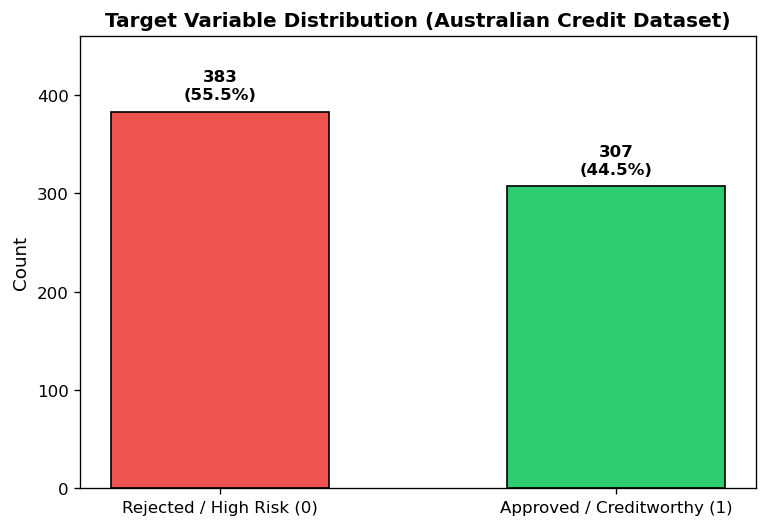

In [34]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))
counts = [np.sum(y == 0), np.sum(y == 1)]
pcts   = [c / len(y) * 100 for c in counts]
bars = ax.bar(["Rejected / High Risk (0)", "Approved / Creditworthy (1)"], counts,
              color=["#ef5350", "#2ecc71"], edgecolor="black", width=0.55)
ax.set_ylim(0, 460)
ax.set_ylabel("Count", fontsize=11)
ax.set_title("Target Variable Distribution (Australian Credit Dataset)", fontsize=12, fontweight="bold")
for bar, c, p in zip(bars, counts, pcts):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 10,
            f"{c}\n({p:.1f}%)", ha="center", va="bottom", fontsize=10, fontweight="bold")
plt.tight_layout()
save_fig("fig1_target_distribution.png")
plt.show()

### Figure 4 – Age and log savings/income distributions by class

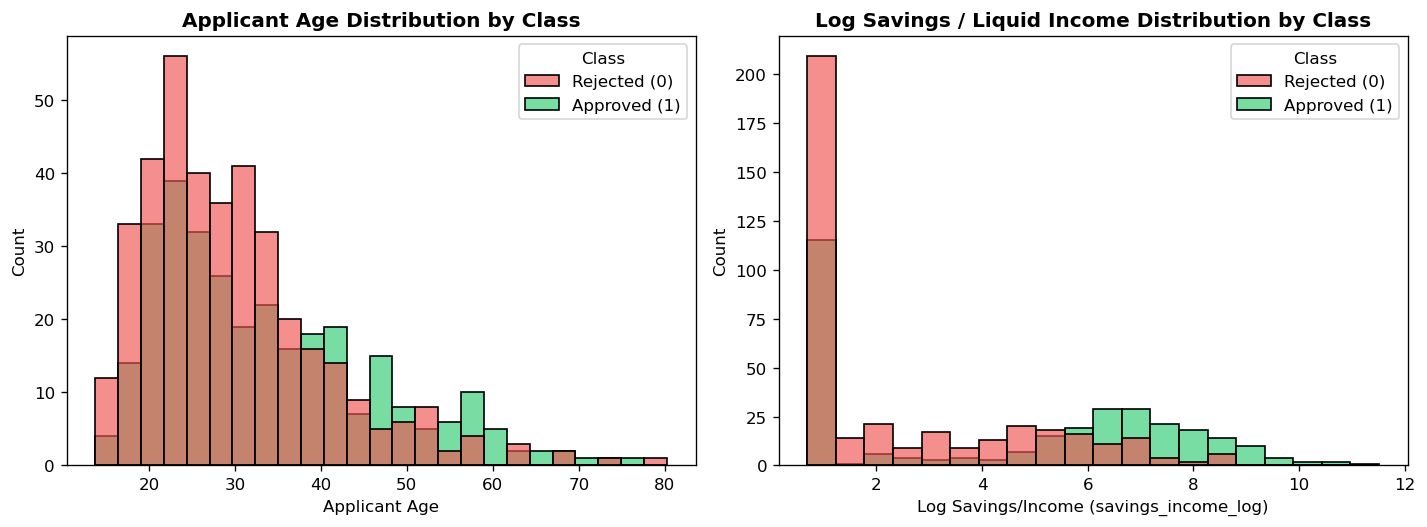

In [7]:
class_labels = np.where(y == 1, "Approved (1)", "Rejected (0)")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.histplot(data=pd.DataFrame({"Applicant Age": X["age"], "Class": class_labels}),
             x="Applicant Age", hue="Class", palette=CLASS_PALETTE,
             bins=25, ax=axes[0], alpha=0.65, edgecolor="black")
axes[0].set_title("Applicant Age Distribution by Class", fontweight="bold")

sns.histplot(data=pd.DataFrame({"Log Savings/Income (savings_income_log)": X["savings_income_log"], "Class": class_labels}),
             x="Log Savings/Income (savings_income_log)", hue="Class", palette=CLASS_PALETTE,
             bins=20, ax=axes[1], alpha=0.65, edgecolor="black")
axes[1].set_title("Log Savings / Liquid Income Distribution by Class", fontweight="bold")
plt.tight_layout()
save_fig("fig4_numerical_distributions.png")
plt.show()

### Figure 3 – Correlation heatmap (continuous features + target)

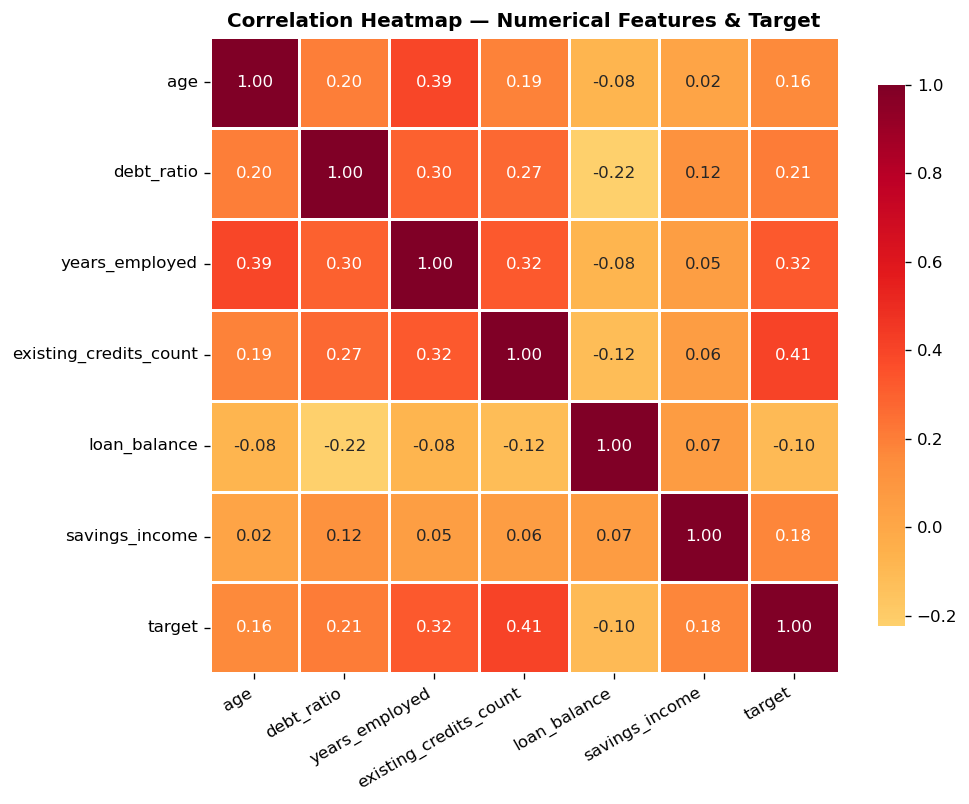

In [8]:
corr_df = X[num_cols].copy()
corr_df["target"] = y
corr_mat = corr_df.corr()

fig, ax = plt.subplots(figsize=(8.5, 6.8))
sns.heatmap(corr_mat, annot=True, fmt=".2f", cmap="YlOrRd", center=0.15,
            linewidths=0.8, ax=ax, cbar_kws={"shrink": 0.85})
ax.set_title("Correlation Heatmap — Numerical Features & Target", fontsize=12, fontweight="bold")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
save_fig("fig3_correlation_heatmap.png")
plt.show()

###  Figure 2 – Credit history & employment profiles by risk class

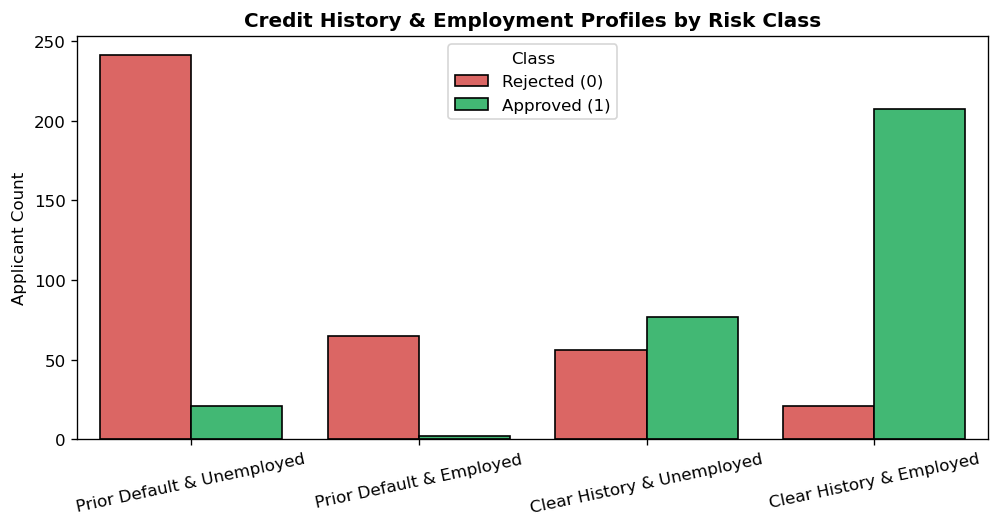

,Applicants,Approved,Approval_Rate
Profile,,,
Prior Default & Unemployed,262,21,8.0
Prior Default & Employed,67,2,3.0
Clear History & Unemployed,133,77,57.9
Clear History & Employed,228,207,90.8


In [9]:
profile = np.select(
    [(X["no_prior_default"]==0) & (X["is_employed"]==0),
     (X["no_prior_default"]==0) & (X["is_employed"]==1),
     (X["no_prior_default"]==1) & (X["is_employed"]==0),
     (X["no_prior_default"]==1) & (X["is_employed"]==1)],
    ["Prior Default & Unemployed", "Prior Default & Employed",
     "Clear History & Unemployed", "Clear History & Employed"],
    default="Other"
)
cat_summary = pd.DataFrame({"Profile": profile, "Class": class_labels})
order_list = ["Prior Default & Unemployed", "Prior Default & Employed",
              "Clear History & Unemployed", "Clear History & Employed"]

fig, ax = plt.subplots(figsize=(8.5, 4.5))
sns.countplot(data=cat_summary, x="Profile", hue="Class", order=order_list,
              palette=CLASS_PALETTE, edgecolor="black", ax=ax)
ax.set_title("Credit History & Employment Profiles by Risk Class", fontsize=12, fontweight="bold")
ax.set_xlabel("")
ax.set_ylabel("Applicant Count")
plt.xticks(rotation=12)
plt.tight_layout()
save_fig("fig2_credit_history_by_class.png")
plt.show()

# Approval rate per profile (supports the Sec. IV-A discussion)
profile_tbl = (cat_summary.assign(approved=(y == 1))
               .groupby("Profile")["approved"].agg(Applicants="count", Approved="sum", Approval_Rate="mean")
               .reindex(order_list))
profile_tbl["Approval_Rate"] = (profile_tbl["Approval_Rate"] * 100).round(1)
profile_tbl

### Table III – Numeric summary by class (mean ± SD) and correlation with approval

In [10]:
print("=" * 85)
print("EDA NUMERIC SUMMARY (paper Table III):")
print("=" * 85)
for c in num_cols:
    m0, s0 = X.loc[y==0, c].mean(), X.loc[y==0, c].std()
    m1, s1 = X.loc[y==1, c].mean(), X.loc[y==1, c].std()
    r_val  = corr_mat.loc[c, "target"]
    print(f"{c:22s} | Class 0 (Rejected): {m0:8.2f} ± {s0:8.2f} | Class 1 (Approved): {m1:8.2f} ± {s1:8.2f} | r = {r_val:+.4f}")

EDA NUMERIC SUMMARY (paper Table III):
age                    | Class 0 (Rejected):    29.85 ±    10.78 | Class 1 (Approved):    33.71 ±    12.77 | r = +0.1616
debt_ratio             | Class 0 (Rejected):     3.84 ±     4.34 | Class 1 (Approved):     5.90 ±     5.47 | r = +0.2063
years_employed         | Class 0 (Rejected):     1.26 ±     2.12 | Class 1 (Approved):     3.43 ±     4.12 | r = +0.3225
existing_credits_count | Class 0 (Rejected):     0.63 ±     1.90 | Class 1 (Approved):     4.61 ±     6.32 | r = +0.4064
loan_balance           | Class 0 (Rejected):   199.41 ±   179.91 | Class 1 (Approved):   164.80 ±   160.20 | r = -0.1000
savings_income         | Class 0 (Rejected):   199.61 ±   671.61 | Class 1 (Approved):  2039.86 ±  7659.76 | r = +0.1757


## 4. Leakage-Free Preprocessing & 5-Fold CV Caching


### 4.1 Stratified train / test split (80 / 20)

In [11]:
woe_num_cols = all_num_cols + [f"{c}_woe" for c in cat_cols_for_woe]

strat_key = y.astype(str) + "_" + X["no_prior_default"].astype(int).astype(str)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=strat_key, random_state=SPLIT_SEED
)
print(f"Train: {X_train.shape} | Test: {X_test.shape}")
print(f"Test set: {(y_test==0).sum()} rejected, {(y_test==1).sum()} approved")

Train: (552, 28) | Test: (138, 28)
Test set: 76 rejected, 62 approved


### 4.2 Preprocessing function (Bayesian WoE → median impute → RobustScaler → one-hot)

In [12]:
def fit_transform_no_smote(X_tr_raw, y_tr_raw, X_va_raw, X_te_raw, smoothing=WOE_SMOOTH):
    # Leakage-free Bayesian WoE + RobustScaler + OHE (no SMOTE). Fit on X_tr only.
    X_tr = X_tr_raw.reset_index(drop=True).copy()
    X_va = X_va_raw.reset_index(drop=True).copy()
    X_te = X_te_raw.reset_index(drop=True).copy()
    y_tr_arr = np.asarray(y_tr_raw)

    total_0 = max(np.sum(y_tr_arr == 0), 1)
    total_1 = max(np.sum(y_tr_arr == 1), 1)

    for col in cat_cols_for_woe:
        stats = (pd.DataFrame({"cat": X_tr[col].astype(str), "y": y_tr_arr})
                   .groupby("cat")["y"].agg(["count", "sum"]))
        pos = stats["sum"] + smoothing
        neg = (stats["count"] - stats["sum"]) + smoothing
        woe_map = np.log((pos / (total_1 + smoothing * len(stats))) /
                         (neg / (total_0 + smoothing * len(stats)))).to_dict()

        X_tr[f"{col}_woe"] = X_tr[col].astype(str).map(woe_map).fillna(0.0)
        X_va[f"{col}_woe"] = X_va[col].astype(str).map(woe_map).fillna(0.0)
        X_te[f"{col}_woe"] = X_te[col].astype(str).map(woe_map).fillna(0.0)

    ct = ColumnTransformer(
        transformers=[
            ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                              ("sc",  RobustScaler())]), woe_num_cols),
            ("cat", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), multi_cat_cols),
        ],
        remainder="drop"
    )
    X_tr_mat = np.nan_to_num(ct.fit_transform(X_tr), nan=0.0, posinf=0.0, neginf=0.0)
    X_va_mat = np.nan_to_num(ct.transform(X_va),     nan=0.0, posinf=0.0, neginf=0.0)
    X_te_mat = np.nan_to_num(ct.transform(X_te),     nan=0.0, posinf=0.0, neginf=0.0)
    return X_tr_mat, y_tr_arr, X_va_mat, X_te_mat, ct

### 4.3 Cache the five CV folds and the full-train / test matrices

In [13]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cached_folds = []

for tr_idx, val_idx in cv.split(X_train, y_train):
    X_tr_m, y_tr_m, X_val_m, X_te_fold, _ = fit_transform_no_smote(
        X_train.iloc[tr_idx], y_train[tr_idx], X_train.iloc[val_idx], X_test
    )
    cached_folds.append((tr_idx, val_idx, X_tr_m, y_tr_m, X_val_m, X_te_fold))

# Full-training-set transform (used for the final models and explainers)
X_train_full, y_train_full, _, X_test_mat, fitted_ct = fit_transform_no_smote(
    X_train, y_train, X_test, X_test
)

ohe_names     = list(fitted_ct.named_transformers_["cat"].get_feature_names_out(multi_cat_cols))
feature_names = woe_num_cols + ohe_names

print(f"Train Shape: {X_train_full.shape} | Untouched Test Shape: {X_test_mat.shape} | Total Features: {len(feature_names)}")

Train Shape: (552, 54) | Untouched Test Shape: (138, 54) | Total Features: 54


## 5. Models

### 5.1 Deep Gated Tabular Network (DGTN)

In [14]:
class DeepGatedTabularNet:
    # TabNet-style soft feature gate + multi-scale MLP ensemble.
    def __init__(self, random_state=42):
        self.random_state = random_state

    def fit(self, X, y):
        # 1) Sparse L1-logistic model scores each input -> soft gate in [0.5, 1.0]
        gate_lr = LogisticRegression(C=0.25, penalty="l1", solver="liblinear",
                                     random_state=self.random_state)
        gate_lr.fit(X, y)
        importance = np.abs(gate_lr.coef_[0])
        self.feature_gate_ = 0.5 + 0.5 * (importance / (np.max(importance) + 1e-6))

        # 2) Residual-style input [x, g*x]
        X_res = np.hstack([X, X * self.feature_gate_])

        # 3) Three MLPs with different depth / activation / regularisation
        self.mlps_ = [
            MLPClassifier(hidden_layer_sizes=(128, 64, 32), activation="relu", alpha=1.2,
                          learning_rate_init=0.002, max_iter=600, random_state=self.random_state),
            MLPClassifier(hidden_layer_sizes=(64, 32), activation="tanh", alpha=1.5,
                          learning_rate_init=0.003, max_iter=600, random_state=self.random_state + 1),
            MLPClassifier(hidden_layer_sizes=(96, 48), activation="relu", alpha=2.0,
                          learning_rate_init=0.002, max_iter=600, random_state=self.random_state + 2),
        ]
        for net in self.mlps_:
            net.fit(X_res, y)
        return self

    def predict_proba(self, X):
        X_res = np.hstack([X, X * self.feature_gate_])
        return np.mean([net.predict_proba(X_res) for net in self.mlps_], axis=0)

### 5.2 Model definitions (paper Table II)

In [15]:
DGTN_NAME = "Deep Gated Tabular Net (DL)"

base_models = {
    "Logistic Regression": LogisticRegression(C=0.15, penalty="l2", max_iter=1000, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(
        n_estimators=400, max_depth=6, min_samples_leaf=4, max_features="sqrt",
        random_state=RANDOM_STATE, n_jobs=1),
    "XGBoost": XGBClassifier(
        n_estimators=160, max_depth=3, learning_rate=0.025, subsample=0.80,
        colsample_bytree=0.70, min_child_weight=5, reg_alpha=1.2, reg_lambda=3.0,
        eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=1),
    DGTN_NAME: DeepGatedTabularNet(random_state=RANDOM_STATE),
}

# Silent hybrid members (trained, but excluded from the benchmark tables)
member_only_models = {
    "Extra Trees": ExtraTreesClassifier(
        n_estimators=400, max_depth=7, min_samples_leaf=3, max_features="sqrt",
        random_state=RANDOM_STATE, n_jobs=1),
    "CatBoost": CatBoostClassifier(
        iterations=250, depth=4, learning_rate=0.025, l2_leaf_reg=6.0,
        verbose=0, thread_count=1, random_seed=RANDOM_STATE),
}

all_models = {**base_models, **member_only_models}

def make_model(name):
    # Fresh, unfitted copy of a model (DGTN is a custom class, so it is rebuilt instead of cloned).
    if name == DGTN_NAME:
        return DeepGatedTabularNet(random_state=RANDOM_STATE)
    return clone(all_models[name])

print("Benchmarked :", list(base_models))
print("Ensemble-only:", list(member_only_models))

Benchmarked : ['Logistic Regression', 'Random Forest', 'XGBoost', 'Deep Gated Tabular Net (DL)']
Ensemble-only: ['Extra Trees', 'CatBoost']


### 5.3 Train every model: out-of-fold (OOF) predictions + test predictions


In [16]:
oof_probs, test_probs, cv_aucs, fitted_models = {}, {}, {}, {}

for name in all_models:
    oof_p       = np.zeros(len(X_train))
    fold_test_p = np.zeros((len(cached_folds), len(X_test)))
    fold_aucs   = []

    for i, (tr_idx, val_idx, X_tr_m, y_tr_m, X_val_m, X_te_fold) in enumerate(cached_folds):
        m = make_model(name)
        m.fit(X_tr_m, y_tr_m)
        p_val = m.predict_proba(X_val_m)[:, 1]
        oof_p[val_idx] = p_val
        fold_aucs.append(roc_auc_score(y_train[val_idx], p_val))
        fold_test_p[i] = m.predict_proba(X_te_fold)[:, 1]

    m_full = make_model(name)
    m_full.fit(X_train_full, y_train_full)

    oof_probs[name]     = oof_p
    test_probs[name]    = 0.5 * m_full.predict_proba(X_test_mat)[:, 1] + 0.5 * np.mean(fold_test_p, axis=0)
    cv_aucs[name]       = fold_aucs
    fitted_models[name] = m_full
    print(f"  ✓ {name:30s} CV AUC = {np.mean(fold_aucs):.4f} ± {np.std(fold_aucs):.4f}")

  ✓ Logistic Regression            CV AUC = 0.9306 ± 0.0265
  ✓ Random Forest                  CV AUC = 0.9388 ± 0.0205
  ✓ XGBoost                        CV AUC = 0.9367 ± 0.0225
  ✓ Deep Gated Tabular Net (DL)    CV AUC = 0.9290 ± 0.0215
  ✓ Extra Trees                    CV AUC = 0.9309 ± 0.0196
  ✓ CatBoost                       CV AUC = 0.9376 ± 0.0211


### 5.4 Proposed Hybrid-TabNet-Ensemble
1. Convert each member's OOF probability to a **logit** and recalibrate with **Platt scaling**.
2. Weight members by `w_k ∝ max(AUC_k − 0.85, 0.01)²` (cross-validated AUC).
3. Average the calibrated probabilities:  
   `p_hybrid(x) = Σ_k w_k · σ(a_k · logit(p_k(x)) + b_k)`

Six members: Logistic Regression, Random Forest, Extra Trees, XGBoost, DGTN, CatBoost.

In [17]:
PROP_NAME   = "Proposed Hybrid-TabNet-Ensemble"
member_keys = ["Logistic Regression", "Random Forest", "Extra Trees",
               "XGBoost", DGTN_NAME, "CatBoost"]

def to_logit(p, eps=1e-6):
    p = np.clip(p, eps, 1 - eps)
    return np.log(p / (1 - p)).reshape(-1, 1)

cal_oof_list, cal_test_list, auc_weights = [], [], []
for k in member_keys:
    oof_logit, test_logit = to_logit(oof_probs[k]), to_logit(test_probs[k])

    platt = LogisticRegression(C=1.0, random_state=RANDOM_STATE)
    platt.fit(oof_logit, y_train)
    cal_oof_list.append(platt.predict_proba(oof_logit)[:, 1])
    cal_test_list.append(platt.predict_proba(test_logit)[:, 1])
    auc_weights.append(max(np.mean(cv_aucs[k]) - 0.85, 0.01) ** 2)

oof_probs[PROP_NAME]  = np.average(cal_oof_list,  axis=0, weights=auc_weights)
test_probs[PROP_NAME] = np.average(cal_test_list, axis=0, weights=auc_weights)
cv_aucs[PROP_NAME]    = [roc_auc_score(y_train[val_idx], oof_probs[PROP_NAME][val_idx])
                         for _, val_idx, _, _, _, _ in cached_folds]

# Ensemble weights (paper: ~15-19% each, close to uniform)
w = np.array(auc_weights) / np.sum(auc_weights)
pd.DataFrame({"Member": member_keys,
              "Mean CV AUC": [round(np.mean(cv_aucs[k]), 4) for k in member_keys],
              "Ensemble weight": np.round(w, 4)})

,Member,Mean CV AUC,Ensemble weight
0,Logistic Regression,0.9306,0.1534
1,Random Forest,0.9388,0.1860
2,Extra Trees,0.9309,0.1545
3,XGBoost,0.9367,0.1776
4,Deep Gated Tabular Net (DL),0.9290,0.1472
5,CatBoost,0.9376,0.1813


## 6. Evaluation (held-out test set, n = 138)
Approval (class 1) is the positive class. Each model's decision threshold is chosen from a 33-point grid on **[0.42, 0.58]** by maximising accuracy on the **out-of-fold training predictions** — never on the test set.

### 6.1 Full benchmark table

In [18]:
reported_models = list(base_models) + [PROP_NAME]      # the 5 models in the paper
grid = np.linspace(0.42, 0.58, 33)

def wilson_ci(k, n, z=1.96):
    # 95% Wilson score interval for a proportion k/n.
    p = k / n
    denom  = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    half   = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return centre - half, centre + half

results, test_preds = [], {}
for name in reported_models:
    oof_p, test_p = oof_probs[name], test_probs[name]
    best_t = max(grid, key=lambda t: accuracy_score(y_train, (oof_p >= t).astype(int)))
    preds  = (test_p >= best_t).astype(int)
    test_preds[name] = preds
    tn, fp, fn, tp = confusion_matrix(y_test, preds).ravel()
    lo, hi = wilson_ci(tn + tp, len(y_test))

    results.append({
        "Model": name,
        "Opt Thresh": round(best_t, 3),
        "Accuracy": round(accuracy_score(y_test, preds), 4),
        "Precision": round(precision_score(y_test, preds, zero_division=0), 4),
        "Recall": round(recall_score(y_test, preds, zero_division=0), 4),
        "F1-Score": round(f1_score(y_test, preds, zero_division=0), 4),
        "Specificity": round(tn / (tn + fp), 4),
        "MCC": round(matthews_corrcoef(y_test, preds), 4),
        "Test ROC-AUC": round(roc_auc_score(y_test, test_p), 4),
        "CV AUC Mean": round(np.mean(cv_aucs[name]), 4),
        "CV AUC Std": round(np.std(cv_aucs[name]), 4),
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
        "Acc 95% CI": f"{lo:.2f}-{hi:.2f}",
    })

results_df = (pd.DataFrame(results)
              .sort_values(by=["Accuracy", "Test ROC-AUC"], ascending=False)
              .reset_index(drop=True))

print("=" * 150)
print(f"FULL BENCHMARK & CONFUSION MATRIX RESULTS (n_test = {len(y_test)})")
print("=" * 150)
print(results_df.to_string(index=False))

FULL BENCHMARK & CONFUSION MATRIX RESULTS (n_test = 138)
                          Model  Opt Thresh  Accuracy  Precision  Recall  F1-Score  Specificity    MCC  Test ROC-AUC  CV AUC Mean  CV AUC Std  TN  FP  FN  TP Acc 95% CI
Proposed Hybrid-TabNet-Ensemble       0.550    0.8841     0.8485  0.9032    0.8750       0.8684 0.7684        0.9433       0.9403      0.0192  66  10   6  56  0.82-0.93
            Logistic Regression       0.475    0.8768     0.8358  0.9032    0.8682       0.8553 0.7549        0.9391       0.9306      0.0265  65  11   6  56  0.81-0.92
                  Random Forest       0.480    0.8768     0.8261  0.9194    0.8702       0.8421 0.7575        0.9391       0.9388      0.0205  64  12   5  57  0.81-0.92
                        XGBoost       0.500    0.8696     0.8143  0.9194    0.8636       0.8289 0.7445        0.9486       0.9367      0.0225  63  13   5  57  0.80-0.92
    Deep Gated Tabular Net (DL)       0.550    0.8623     0.8308  0.8710    0.8504       0.8553 0.

### 6.2 Paper Tables IV, V and VI

In [19]:
short = {PROP_NAME: "Hybrid (proposed)", DGTN_NAME: "DGTN (deep)"}
disp  = results_df.assign(Model=results_df["Model"].replace(short))

print("TABLE IV — TEST-SET PERFORMANCE (approval = positive class)")
print(disp[["Model", "Accuracy", "Precision", "Recall", "F1-Score", "Test ROC-AUC", "Opt Thresh"]]
      .to_string(index=False))

print("\nTABLE V — CONFUSION MATRICES, SPECIFICITY, MCC, 95% WILSON CI FOR ACCURACY")
print(disp[["Model", "TN", "FP", "FN", "TP", "Specificity", "MCC", "Acc 95% CI"]].to_string(index=False))

print("\nTABLE VI — FIVE-FOLD STRATIFIED CV ROC-AUC (TRAINING SET)")
print(disp.sort_values("CV AUC Mean", ascending=False)[["Model", "CV AUC Mean", "CV AUC Std"]].to_string(index=False))

TABLE IV — TEST-SET PERFORMANCE (approval = positive class)
              Model  Accuracy  Precision  Recall  F1-Score  Test ROC-AUC  Opt Thresh
  Hybrid (proposed)    0.8841     0.8485  0.9032    0.8750        0.9433       0.550
Logistic Regression    0.8768     0.8358  0.9032    0.8682        0.9391       0.475
      Random Forest    0.8768     0.8261  0.9194    0.8702        0.9391       0.480
            XGBoost    0.8696     0.8143  0.9194    0.8636        0.9486       0.500
        DGTN (deep)    0.8623     0.8308  0.8710    0.8504        0.9300       0.550

TABLE V — CONFUSION MATRICES, SPECIFICITY, MCC, 95% WILSON CI FOR ACCURACY
              Model  TN  FP  FN  TP  Specificity    MCC Acc 95% CI
  Hybrid (proposed)  66  10   6  56       0.8684 0.7684  0.82-0.93
Logistic Regression  65  11   6  56       0.8553 0.7549  0.81-0.92
      Random Forest  64  12   5  57       0.8421 0.7575  0.81-0.92
            XGBoost  63  13   5  57       0.8289 0.7445  0.80-0.92
        DGTN (deep)

### 6.3 Confusion matrices (visual)

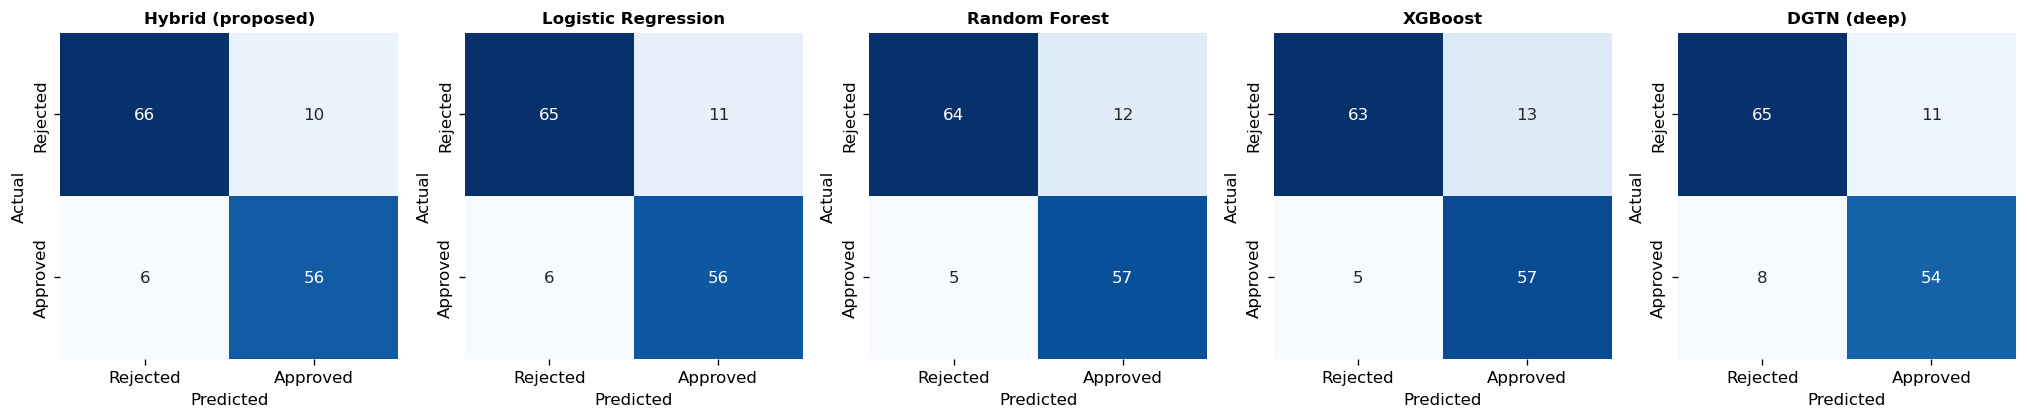

In [20]:
order = results_df["Model"].tolist()
fig, axes = plt.subplots(1, len(order), figsize=(3.4 * len(order), 3.6))
for ax, name in zip(axes, order):
    cm = confusion_matrix(y_test, test_preds[name])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Rejected", "Approved"], yticklabels=["Rejected", "Approved"])
    ax.set_title(short.get(name, name), fontsize=10, fontweight="bold")
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout()
save_fig("confusion_matrices.png")
plt.show()

## 7. SHAP Global Explanations (XGBoost)
Exact TreeSHAP is applied to the fitted XGBoost model on the 138 test applications; attributions are in **log-odds of approval**.

> **Reading note:** after RobustScaler, binary indicators are shifted so the majority category sits at 0. `no_prior_default` therefore appears as **0 = clean history** and **−1 = prior default**.

### 7.1 Compute SHAP values & Table VII

In [21]:
xgb_model = fitted_models["XGBoost"]
explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_test_mat)
if isinstance(shap_values, list):
    shap_values = shap_values[1]

X_test_df = pd.DataFrame(X_test_mat, columns=feature_names)

shap_table = pd.DataFrame({
    "Feature": feature_names,
    "Mean_Abs_SHAP":    np.round(np.mean(np.abs(shap_values), axis=0), 4),
    "Mean_Signed_SHAP": np.round(np.mean(shap_values, axis=0), 4),
}).sort_values(by="Mean_Abs_SHAP", ascending=False).reset_index(drop=True)
shap_table.index += 1

print("=" * 80)
print("TABLE VII: TOP 15 FEATURES BY MEAN ABSOLUTE SHAP VALUE")
print("=" * 80)
print(shap_table.head(15).to_string())

TABLE VII: TOP 15 FEATURES BY MEAN ABSOLUTE SHAP VALUE
                   Feature  Mean_Abs_SHAP  Mean_Signed_SHAP
1         no_prior_default         0.9969           -0.0245
2       credit_emp_synergy         0.3541           -0.0047
3         default_x_tenure         0.2742           -0.0222
4     net_liquidity_spread         0.2315            0.0193
5   bank_customer_type_woe         0.1343            0.0224
6        default_x_savings         0.1090            0.0078
7              is_employed         0.0869           -0.0147
8       marital_status_woe         0.0783           -0.0086
9        debt_to_age_ratio         0.0746           -0.0448
10          savings_income         0.0740           -0.0158
11          years_employed         0.0709            0.0066
12            loan_balance         0.0687            0.0035
13       default_x_credits         0.0681            0.0075
14              debt_ratio         0.0663           -0.0296
15  existing_credits_count         0.0386    

### 7.2 Figure 6 – SHAP bar plot (top 15)

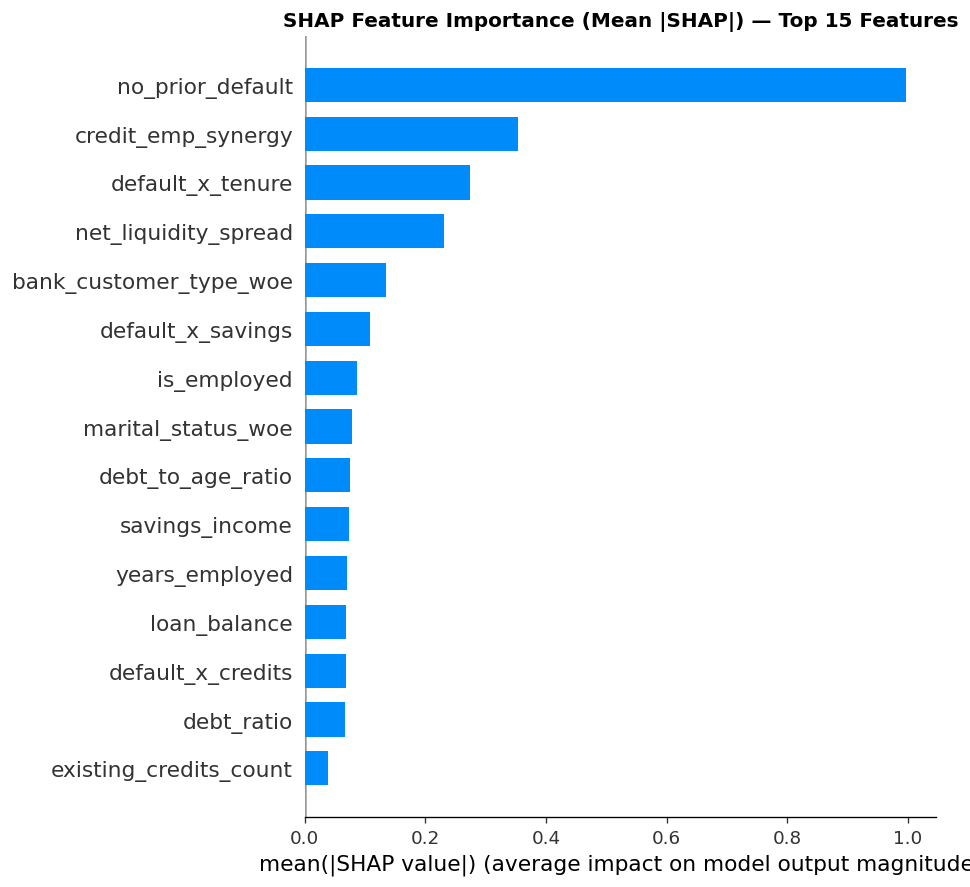

In [22]:
plt.figure(figsize=(8.5, 5.5))
shap.summary_plot(shap_values, X_test_df, plot_type="bar", max_display=15, show=False)
plt.title("SHAP Feature Importance (Mean |SHAP|) — Top 15 Features", fontsize=12, fontweight="bold")
plt.tight_layout()
save_fig("fig6_shap_bar.png")
plt.show()

### 7.3 Figure 5 – SHAP beeswarm summary (top 15)

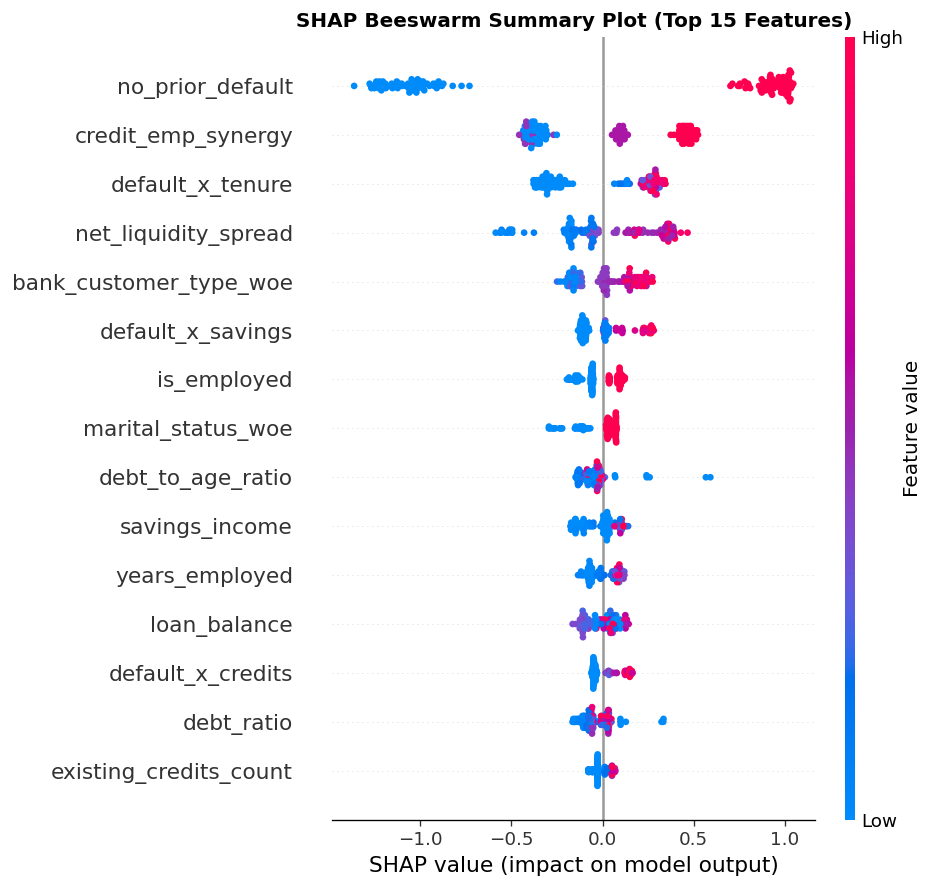

In [23]:
plt.figure(figsize=(9, 5.5))
shap.summary_plot(shap_values, X_test_df, max_display=15, show=False)
plt.title("SHAP Beeswarm Summary Plot (Top 15 Features)", fontsize=12, fontweight="bold")
plt.tight_layout()
save_fig("fig5_shap_beeswarm.png")
plt.show()

### 7.4 Figures 9–11 – SHAP dependence plots (top 3 features)

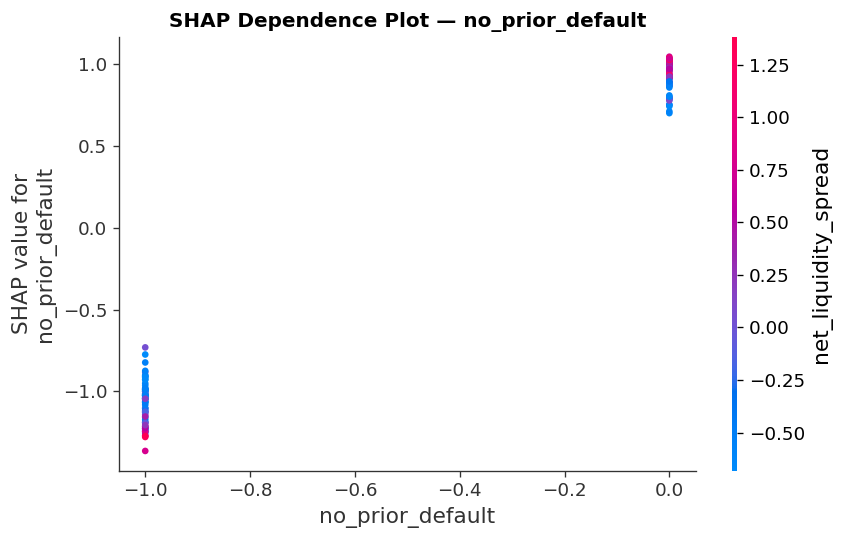

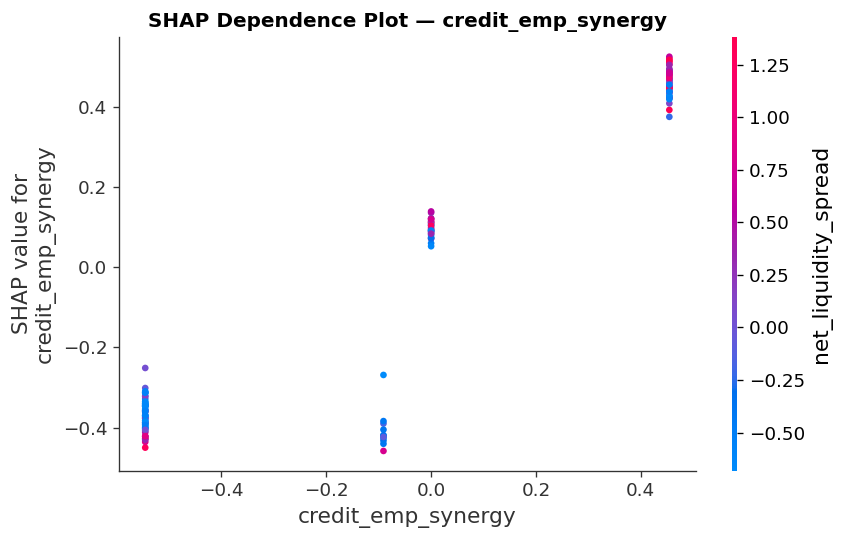

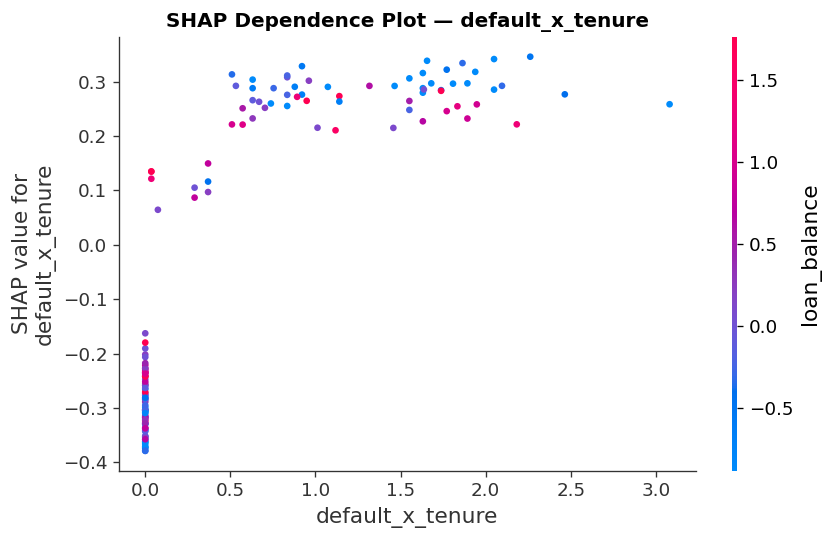

In [24]:
top3_feats = shap_table["Feature"].iloc[:3].tolist()
for fig_no, feat in zip([9, 10, 11], top3_feats):
    fig, ax = plt.subplots(figsize=(7.2, 4.6))
    shap.dependence_plot(feat, shap_values, X_test_df, ax=ax, show=False)
    ax.set_title(f"SHAP Dependence Plot — {feat}", fontsize=12, fontweight="bold")
    plt.tight_layout()
    save_fig(f"fig{fig_no}_shap_dependence_{feat}.png")
    plt.show()

## 8. SHAP Local Explanations
The local example is the **first test applicant who is truly approved and receives a hybrid probability ≥ 0.85**. The rule is fixed in advance (not picked by inspection).

### 8.1 Select the applicant

In [25]:
tp_candidates = np.where((y_test == 1) & (test_probs[PROP_NAME] >= 0.85))[0]
sample_idx = int(tp_candidates[0]) if len(tp_candidates) > 0 else 0

base_val = explainer.expected_value
if isinstance(base_val, (list, np.ndarray)):
    base_val = float(np.atleast_1d(base_val)[-1])

print(f"Selected Local Sample Index: {sample_idx} | True Class: {y_test[sample_idx]} | "
      f"Hybrid Ensemble Prob: {test_probs[PROP_NAME][sample_idx]:.4f}")

Selected Local Sample Index: 0 | True Class: 1 | Hybrid Ensemble Prob: 0.9188


### 8.2 Figure 7 – SHAP waterfall (standalone XGBoost)

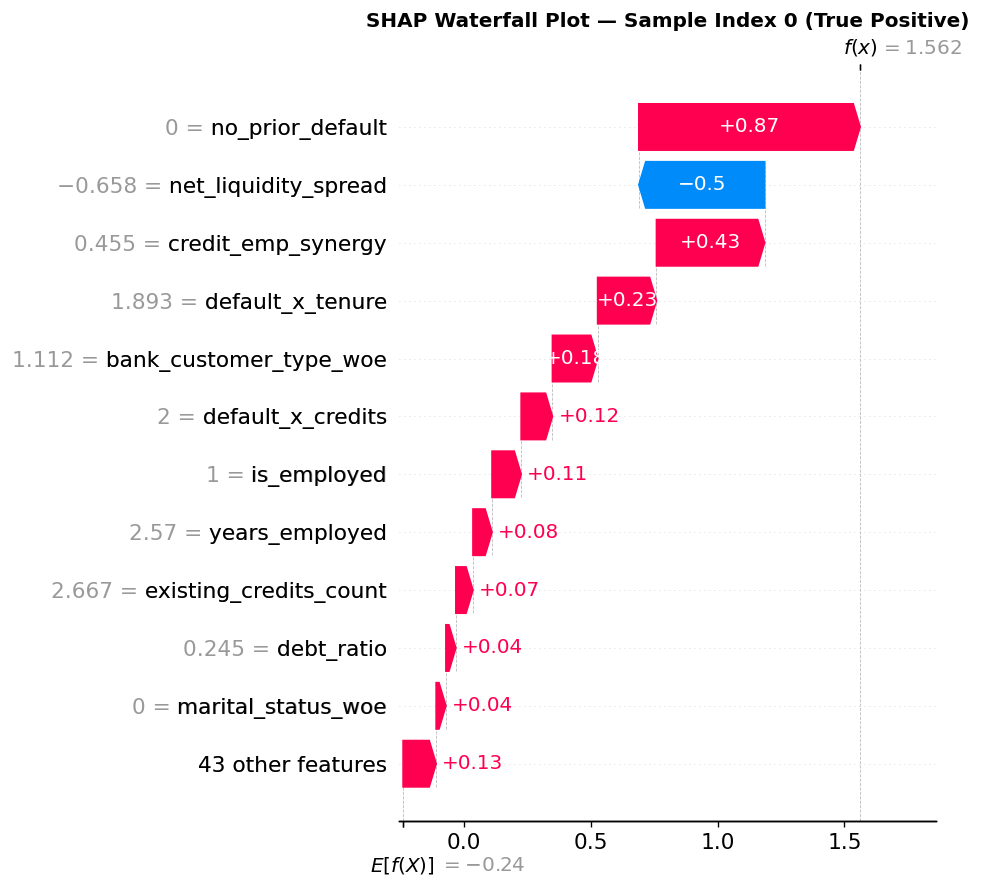

In [26]:
exp_obj = shap.Explanation(
    values=shap_values[sample_idx],
    base_values=base_val,
    data=np.round(X_test_mat[sample_idx], 3),
    feature_names=feature_names,
)
plt.figure(figsize=(9, 5.5))
shap.plots.waterfall(exp_obj, max_display=12, show=False)
plt.title(f"SHAP Waterfall Plot — Sample Index {sample_idx} (True Positive)", fontsize=12, fontweight="bold")
plt.tight_layout()
save_fig("fig7_shap_waterfall_xgb.png")
plt.show()

### 8.3 Figure 8 – Gate-scaled SHAP proxy for the hybrid
A heterogeneous ensemble has no exact tree-based Shapley decomposition. As in the paper (Sec. III-G), hybrid attributions are **approximated** by multiplying each XGBoost SHAP value by the DGTN gate weight. This is an *interpretive proxy*, not an exact Shapley decomposition of the hybrid.

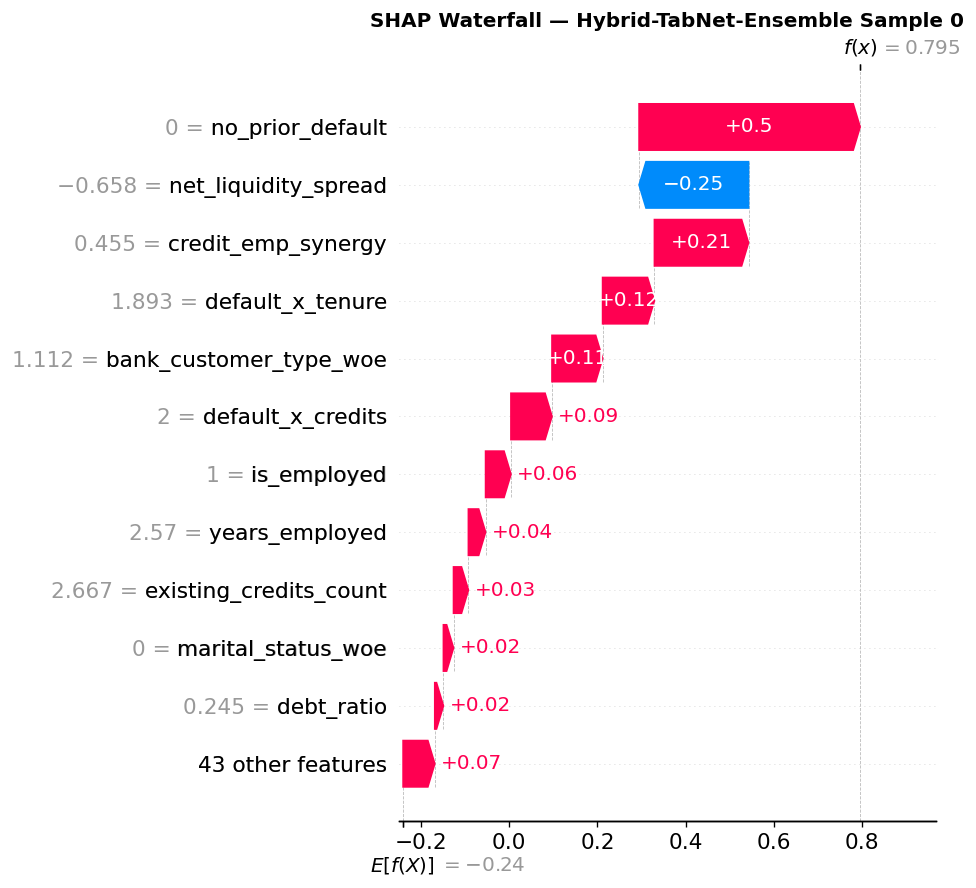

In [27]:
dl_gate = fitted_models[DGTN_NAME].feature_gate_
ens_shap_vals = shap_values[sample_idx] * dl_gate

exp_ens_obj = shap.Explanation(
    values=ens_shap_vals,
    base_values=base_val,
    data=np.round(X_test_mat[sample_idx], 3),
    feature_names=feature_names,
)
plt.figure(figsize=(9, 5.5))
shap.plots.waterfall(exp_ens_obj, max_display=12, show=False)
plt.title(f"SHAP Waterfall — Hybrid-TabNet-Ensemble Sample {sample_idx}", fontsize=12, fontweight="bold")
plt.tight_layout()
save_fig("fig8_shap_waterfall_ensemble.png")
plt.show()

## 9. LIME Cross-Validation vs SHAP (same applicant)
LIME is fitted on the training matrix and applied to the XGBoost probability function. We compare **directional agreement** with SHAP on the top-10 LIME features.

### 9.1 Figure 12 – LIME explanation

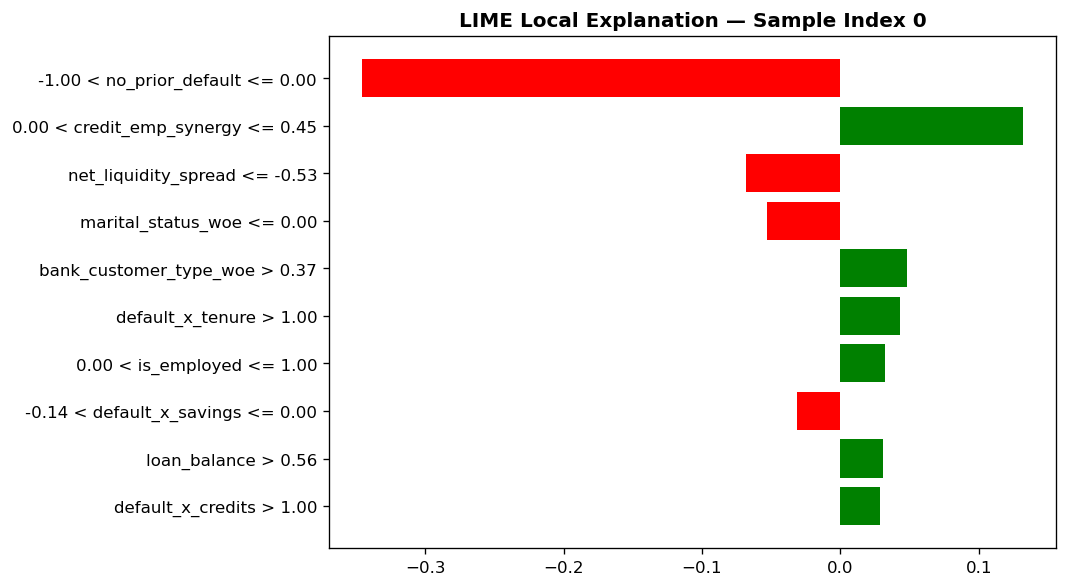

In [28]:
import lime.lime_tabular

lime_explainer = lime.lime_tabular.LimeTabularExplainer(
    X_train_full,
    feature_names=feature_names,
    class_names=["Rejected (0)", "Approved (1)"],
    mode="classification",
    random_state=RANDOM_STATE,
)
lime_exp = lime_explainer.explain_instance(
    X_test_mat[sample_idx],
    fitted_models["XGBoost"].predict_proba,
    num_features=10,
)

fig = lime_exp.as_pyplot_figure()
fig.set_size_inches(9, 5)
plt.title(f"LIME Local Explanation — Sample Index {sample_idx}", fontsize=12, fontweight="bold")
plt.tight_layout()
save_fig("fig12_lime_explanation.png")
plt.show()

### 9.2 Table VIII – SHAP vs LIME directional agreement

In [29]:
comp_rows = []
for f_idx, lime_w in lime_exp.as_map()[1]:
    shap_w = shap_values[sample_idx][f_idx]
    s_dir = "APPROVED (+)" if shap_w >= 0 else "REJECTED (-)"
    l_dir = "APPROVED (+)" if lime_w >= 0 else "REJECTED (-)"
    comp_rows.append({
        "Feature": feature_names[f_idx],
        "SHAP_Value": round(float(shap_w), 4), "SHAP_Direction": s_dir,
        "LIME_Weight": round(float(lime_w), 4), "LIME_Direction": l_dir,
        "Agreement": "Yes" if s_dir == l_dir else "No",
    })
comp_df = pd.DataFrame(comp_rows)

print("=" * 95)
print(f"TABLE VIII: SHAP VS LIME DIRECTIONAL AGREEMENT (SAMPLE INDEX {sample_idx})")
print("=" * 95)
print(comp_df.to_string(index=False))
print(f"Total Directional Agreement: {(comp_df['Agreement']=='Yes').sum()} / {len(comp_df)}")

TABLE VIII: SHAP VS LIME DIRECTIONAL AGREEMENT (SAMPLE INDEX 0)
               Feature  SHAP_Value SHAP_Direction  LIME_Weight LIME_Direction Agreement
      no_prior_default      0.8726   APPROVED (+)      -0.3459   REJECTED (-)        No
    credit_emp_synergy      0.4264   APPROVED (+)       0.1320   APPROVED (+)       Yes
  net_liquidity_spread     -0.4960   REJECTED (-)      -0.0682   REJECTED (-)       Yes
    marital_status_woe      0.0385   APPROVED (+)      -0.0529   REJECTED (-)        No
bank_customer_type_woe      0.1782   APPROVED (+)       0.0485   APPROVED (+)       Yes
      default_x_tenure      0.2320   APPROVED (+)       0.0434   APPROVED (+)       Yes
           is_employed      0.1150   APPROVED (+)       0.0322   APPROVED (+)       Yes
     default_x_savings      0.0252   APPROVED (+)      -0.0316   REJECTED (-)        No
          loan_balance     -0.0192   REJECTED (-)       0.0308   APPROVED (+)        No
     default_x_credits      0.1233   APPROVED (+)       

## 10. Sensitive-Attribute Fairness Audit
The sensitive set comprises `gender`, `age`, the age-derived `debt_to_age_ratio`, and every column derived from `marital_status` and `citizenship_status`.

> Mean |SHAP| shows **how much a model relies on** these inputs. It is *not* a substitute for group-fairness metrics (e.g. equal opportunity), and the halving seen in the hybrid proxy is a mechanical effect of the 0.5 gate — not evidence that the ensemble is fairer.

### 10.1 Table IX – Mean |SHAP| of sensitive features

In [30]:
sens_indices = [
    i for i, f in enumerate(feature_names)
    if f in ("gender", "age", "debt_to_age_ratio")
    or f.startswith("marital_status")
    or f.startswith("citizenship_status")
]

xgb_sens_shap = np.mean(np.abs(shap_values[:, sens_indices]), axis=0)
ens_sens_shap = np.mean(np.abs(shap_values[:, sens_indices] * dl_gate[sens_indices]), axis=0)

fairness_df = pd.DataFrame({
    "Sensitive_Feature": [feature_names[i] for i in sens_indices],
    "XGBoost_Mean_SHAP": np.round(xgb_sens_shap, 4),
    "Hybrid_Ensemble_Mean_SHAP": np.round(ens_sens_shap, 4),
    "Attention_Gate_Weight": np.round(dl_gate[sens_indices], 4),
}).sort_values(by="XGBoost_Mean_SHAP", ascending=False).reset_index(drop=True)

print("=" * 95)
print("TABLE IX: FAIRNESS AUDIT — MEAN |SHAP| OF SENSITIVE DEMOGRAPHIC FEATURES")
print("=" * 95)
print(fairness_df.to_string(index=False))

TABLE IX: FAIRNESS AUDIT — MEAN |SHAP| OF SENSITIVE DEMOGRAPHIC FEATURES
     Sensitive_Feature  XGBoost_Mean_SHAP  Hybrid_Ensemble_Mean_SHAP  Attention_Gate_Weight
    marital_status_woe             0.0783                     0.0465                 0.5943
     debt_to_age_ratio             0.0746                     0.0373                 0.5000
  citizenship_status_2             0.0347                     0.0173                 0.5000
                   age             0.0245                     0.0123                 0.5000
      marital_status_2             0.0081                     0.0041                 0.5000
                gender             0.0046                     0.0023                 0.5000
citizenship_status_woe             0.0000                     0.0000                 0.5000
      marital_status_3             0.0000                     0.0000                 0.5000
  citizenship_status_3             0.0000                     0.0000                 0.5000


### 10.2 Figure 13 – Fairness audit (standalone XGBoost)

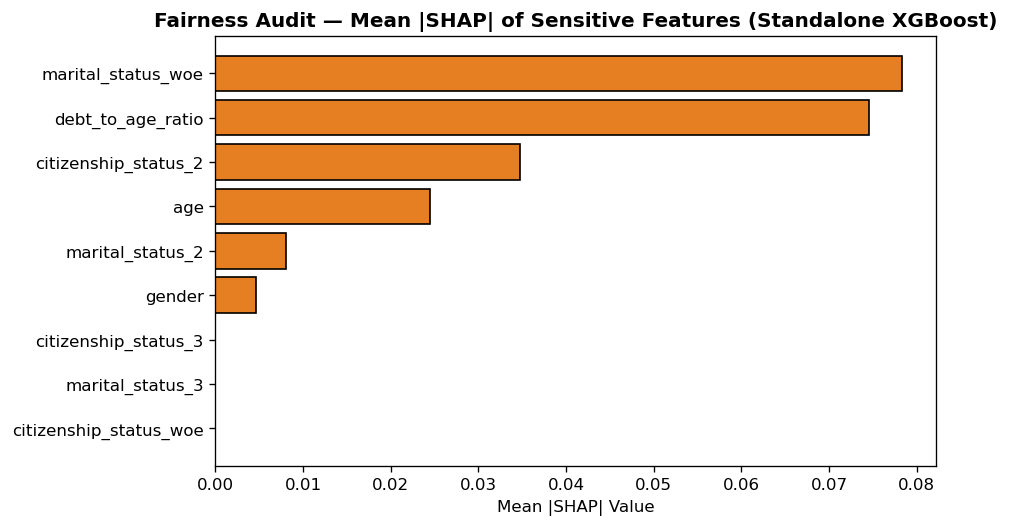

In [31]:
fig, ax = plt.subplots(figsize=(8, 4.5))
plot_df1 = fairness_df.sort_values(by="XGBoost_Mean_SHAP", ascending=True)
ax.barh(plot_df1["Sensitive_Feature"], plot_df1["XGBoost_Mean_SHAP"], color="#e67e22", edgecolor="black")
ax.set_xlabel("Mean |SHAP| Value")
ax.set_title("Fairness Audit — Mean |SHAP| of Sensitive Features (Standalone XGBoost)", fontweight="bold")
plt.tight_layout()
save_fig("fig13_fairness_audit_xgb.png")
plt.show()

### 10.3 Figure 14 – Fairness audit (proposed Hybrid-TabNet-Ensemble, gate-scaled proxy)

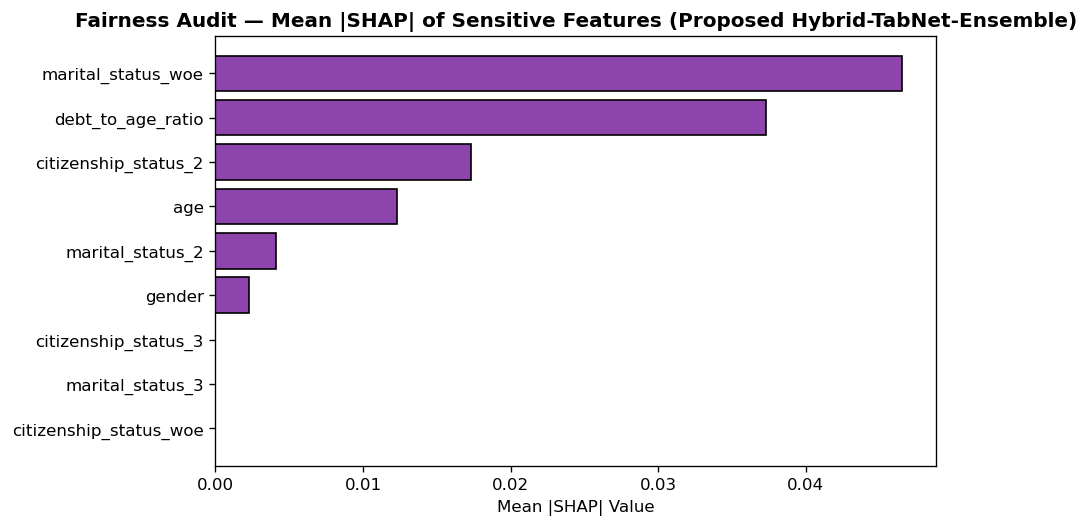

In [32]:
fig, ax = plt.subplots(figsize=(8, 4.5))
plot_df2 = fairness_df.sort_values(by="Hybrid_Ensemble_Mean_SHAP", ascending=True)
ax.barh(plot_df2["Sensitive_Feature"], plot_df2["Hybrid_Ensemble_Mean_SHAP"], color="#8e44ad", edgecolor="black")
ax.set_xlabel("Mean |SHAP| Value")
ax.set_title("Fairness Audit — Mean |SHAP| of Sensitive Features (Proposed Hybrid-TabNet-Ensemble)", fontweight="bold")
plt.tight_layout()
save_fig("fig14_fairness_audit_ensemble.png")
plt.show()

## 11. Output Summary

In [33]:
print("Saved figures:")
for f in sorted(os.listdir(FIG_DIR)):
    print("  •", f)

Saved figures:
  • .ipynb_checkpoints
  • confusion_matrices.png
  • fig10_shap_dependence_credit_emp_synergy.png
  • fig10_shap_waterfall_xgb.png
  • fig11_shap_dependence_default_x_tenure.png
  • fig11_shap_waterfall_ensemble.png
  • fig12_lime_explanation.png
  • fig13_fairness_audit_xgb.png
  • fig14_fairness_audit_ensemble.png
  • fig1_target_distribution.png
  • fig2_credit_history_by_class.png
  • fig2_numerical_distributions.png
  • fig3_correlation_heatmap.png
  • fig4_credit_history_by_class.png
  • fig4_numerical_distributions.png
  • fig5_shap_bar.png
  • fig5_shap_beeswarm.png
  • fig6_shap_bar.png
  • fig6_shap_beeswarm.png
  • fig7_shap_dependence_A8.png
  • fig7_shap_dependence_no_prior_default.png
  • fig7_shap_waterfall_xgb.png
  • fig8_shap_dependence_credit_emp_synergy.png
  • fig8_shap_dependence_fe_A8_synergy.png
  • fig8_shap_waterfall_ensemble.png
  • fig9_shap_dependence_default_x_tenure.png
  • fig9_shap_dependence_fe_A8_x_A7.png
  • fig9_shap_dependence_no_pr